## Analyzing Employer Activity + Zero-Application Job Examples
This notebook covers an analysis on Employer Activity and investigates jobs with zero application in BU CCD Handshake employer engagement data (Spring 2020–Summer 2025).

**Contributors: Tessa Thomas, Shaotai Hu (extension + documentation)**

Last Updated: 3/3/2026

Documentation link https://docs.google.com/document/d/1Bb41HlLYCEw7ClFDz93oFS0ctIXD8MMtMaOlmVGC6xk/edit?usp=sharing

In [3]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")

# ---- File locations ----
# Update DATA_DIR to wherever your CSVs live.
DATA_DIR = "/Users/sviatshevchenko/Desktop/DS539"

#Load in cleaned csv
ep_joined = pd.read_csv(os.path.join(DATA_DIR, "ep_joined.csv"))

# Preview the data
ep_joined.head(5)

/var/folders/hv/tcqdmtjd09j4hgvm2929vjbh0000gn/T/ipykernel_6163/306724861.py:14: DtypeWarning: Columns (4) have mixed types. Specify dtype option on import or set low_memory=False.
  ep_joined = pd.read_csv(os.path.join(DATA_DIR, "ep_joined.csv"))


,name,employer_id,employer_type,employer_creation_date,email,website,employer_size_min,employer_size_max,events_name,event_date,...,employers_name,event_medium,student_attendees_count,employer_name,min_salary,max_salary,job_creation_date,jobs_title,jobs_id,applications_count
0,"lawhon & associates, inc.",392601,environmental services,2019-02-05,kblitzer@lawhon-assoc.com,http://www.lawhon-assoc.com,10.0,50.0,NaN,NaN,...,NaN,NaN,NaN,"lawhon & associates, inc.",20.0,23.0,2025-02-06,environmental technician,9660425.0,0.0
1,"lawhon & associates, inc.",392601,environmental services,2019-02-05,kblitzer@lawhon-assoc.com,http://www.lawhon-assoc.com,10.0,50.0,NaN,NaN,...,NaN,NaN,NaN,"lawhon & associates, inc.",0.0,0.0,2024-01-04,entry-level ecologist,8546132.0,0.0
2,"lawhon & associates, inc.",392601,environmental services,2019-02-05,kblitzer@lawhon-assoc.com,http://www.lawhon-assoc.com,10.0,50.0,NaN,NaN,...,NaN,NaN,NaN,"lawhon & associates, inc.",16.0,16.0,2024-05-08,cultural resource intern,8959118.0,1.0
3,"lawhon & associates, inc.",392601,environmental services,2019-02-05,kblitzer@lawhon-assoc.com,http://www.lawhon-assoc.com,10.0,50.0,NaN,NaN,...,NaN,NaN,NaN,"lawhon & associates, inc.",0.0,0.0,2023-11-02,environmental technician,8397637.0,0.0
4,"lawhon & associates, inc.",392601,environmental services,2019-02-05,kblitzer@lawhon-assoc.com,http://www.lawhon-assoc.com,10.0,50.0,NaN,NaN,...,NaN,NaN,NaN,"lawhon & associates, inc.",45000.0,50000.0,2023-10-30,architectural historian,8387960.0,0.0


## Finding Zero-Application Job Examples
This analysis includes August 2025 data

In [4]:
# Make sure job_creation_date is datetime
ep_joined['job_creation_date'] = pd.to_datetime(ep_joined['job_creation_date'], errors='coerce')

# Filter zero-application jobs from large employers in Aug 2025
zero_app_2025 = ep_joined[
    (ep_joined['applications_count'] == 0) &
    ((ep_joined['employer_size_min'] >= 250) | (ep_joined['employer_size_min'].isna())) &
    (ep_joined['job_creation_date'].dt.year == 2025) &
    (ep_joined['job_creation_date'].dt.month == 8) &
    (ep_joined['events_name'].isna())
].drop_duplicates(subset='jobs_id')

# Take a small sample and display key columns
sample_jobs_2025 = zero_app_2025[['jobs_id','jobs_title','employer_name','applications_count','job_creation_date']].head(15)
sample_jobs_2025

,jobs_id,jobs_title,employer_name,applications_count,job_creation_date
26,10110420.0,"assurance intern (las vegas, nv)",eide bailly llp,0.0,2025-08-04
30,10110612.0,"assurance intern (reno, ut)",eide bailly llp,0.0,2025-08-04
32,10110461.0,"entry level tax associate (las vegas, nv)",eide bailly llp,0.0,2025-08-04
51,10110703.0,tax intern (utah),eide bailly llp,0.0,2025-08-04
53,10159741.0,entry level associate (assurance or tax),eide bailly llp,0.0,2025-08-18
54,10159737.0,accounting intern (assurance or tax),eide bailly llp,0.0,2025-08-18
56,10184381.0,tax controversy and procedure intern (fall 2025),eide bailly llp,0.0,2025-08-21
66,10159729.0,accounting intern (assurance or tax),eide bailly llp,0.0,2025-08-18
85,10110382.0,"tax intern (billings, mt)",eide bailly llp,0.0,2025-08-04
86,10113561.0,tax controversy and procedure intern (fall 2025),eide bailly llp,0.0,2025-08-05


## Analyzing employer activity on Handshake, including job postings and event participation


/var/folders/hv/tcqdmtjd09j4hgvm2929vjbh0000gn/T/ipykernel_6163/3994984192.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=jobs_per_month.index, y=jobs_per_month.values, palette="Blues_d")


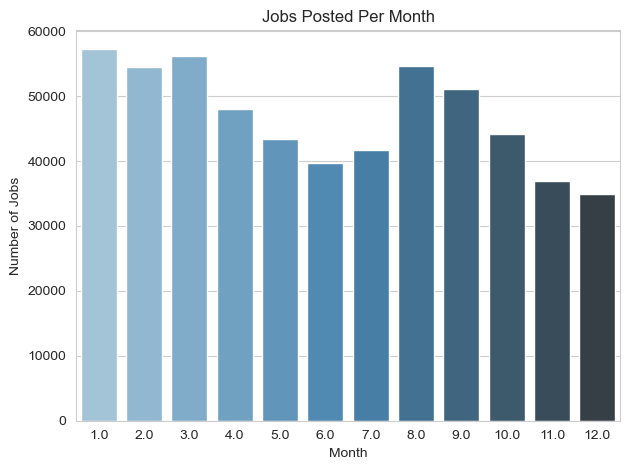

In [5]:
# -----------------------------
# Jobs Posted Per Month (Fixed)
# -----------------------------
ep_joined['job_month'] = ep_joined['job_creation_date'].dt.month
jobs_per_month = ep_joined.groupby('job_month')['jobs_id'].nunique()

sns.barplot(x=jobs_per_month.index, y=jobs_per_month.values, palette="Blues_d")
plt.xlabel("Month")
plt.ylabel("Number of Jobs")
plt.title("Jobs Posted Per Month")
plt.tight_layout()
plt.show()

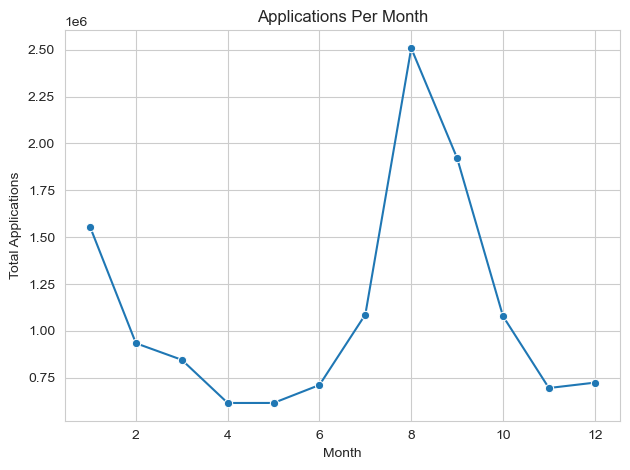

In [6]:
# -----------------------------
# Applications Per Month (New)
# -----------------------------

apps_per_month = ep_joined.groupby('job_month')['applications_count'].sum()

sns.lineplot(x=apps_per_month.index, y=apps_per_month.values, marker="o")
plt.xlabel("Month")
plt.ylabel("Total Applications")
plt.title("Applications Per Month")
plt.tight_layout()
plt.show()


# Details on Definitions Used Below

### Employer Engagement Intensity Score (EEIS): How deeply an employer engages with BU across multiple channels, not just posting jobs.
### Weighted score combination -> EEISe= w1(Job Posts) + w2(Events) + w3(Student Interactions) + w4(Applications)
### Job Application Yield (JAY): How frequently/effectively posted jobs attract student applications. 
### JAY = Applications Count / Jobs Posted    + Salary Signaling Index (SSI) = Avg Salary x JAY, showing whether compensation drives student interest. 
### Event Attendance Yield (EAY): How frequently/effectively hosted events attract student attendees.
### EAY = Student Attendees / Events Hosted
### Define Employer Engagement Breadth (EEB) and Employer Engagement Consistency (EEC) as measures of how active employers are on the handshake platform and a way of segmenting them for visualization, EEB = 1(Posted Jobs) + 1(Hosted Events) and EEC = Active Years / Years Since First Activity.										
### Application Concentration Index (ACI): Whether student interest is spread across postings or concentrated in one job. ACI = (max (Applications per Job)) / Total Applications

## Calculating Job Application Yield

In [7]:
# Aggregate jobs and applications by employer
employer_jobs = ep_joined.groupby('employer_id')['jobs_id'].nunique()

# Deduplicate to one row per employer-job before summing to avoid
# inflation from repeated job rows across multiple event rows in the join
employer_apps = (
    ep_joined
    .dropna(subset=['jobs_id'])
    .drop_duplicates(subset=['employer_id', 'jobs_id'])
    .groupby('employer_id')['applications_count']
    .sum()
)

# Combine into df
employer_inf = pd.DataFrame({
    'total_jobs': employer_jobs,
    'total_applications': employer_apps
})

# Calculate JAY
employer_inf['JAY'] = employer_inf['total_applications'] / employer_inf['total_jobs']

# Add employer names
employer_inf['employer_name'] = ep_joined.groupby('employer_id')['employer_name'].first()

**Note:** Job Application Yield (JAY): How frequently/effectively posted jobs attract student applications.

JAY = Applications Count / Jobs Posted  

In [8]:
# Display top 10 by JAY
top_jay = employer_inf.sort_values('JAY', ascending=False)
top_jay[['employer_name', 'total_jobs', 'total_applications', 'JAY']].head(10) # <- change number in parantheses to display more

,employer_name,total_jobs,total_applications,JAY
employer_id,,,,
27346,delta partners,2,862.0,431.0
1043347,anqora consulting,1,286.0,286.0
1000251,encora therapeutics,1,283.0,283.0
517355,vermilion rock,1,223.0,223.0
974673,fundamental research labs,1,181.0,181.0
98259,computer trust corporation,1,171.0,171.0
999976,global quality partners,1,156.0,156.0
978345,sharpstakes,1,152.0,152.0
1002531,compliers,1,150.0,150.0


In [9]:
# Display bottom 10 by JAY
least_jay = employer_inf.sort_values('JAY', ascending=True)
least_jay[['employer_name', 'total_jobs', 'total_applications', 'JAY']].head(10)

,employer_name,total_jobs,total_applications,JAY
employer_id,,,,
1061634,alumboost,1,0.0,0.0
221927,the school district of university city,1,0.0,0.0
741403,parasol structures inc,1,0.0,0.0
741386,guy nielson company,1,0.0,0.0
741341,"funding opportunities america, llc.",1,0.0,0.0
741290,david n. deutsch & company | theboardadvisor,3,0.0,0.0
741275,"cornell cooperative extension, putnam",1,0.0,0.0
222140,the center for alaskan coastal studies,7,0.0,0.0
222165,new providence board of education,2,0.0,0.0


In [10]:
# Display top 10 specific employers by JAY
target_ids = [14072, 14613, 8530, 14620, 9226, 13661, 39013, 11227, 12397, 15384]

top_jay_specific = employer_inf[employer_inf.index.isin(target_ids)].sort_values('JAY', ascending=False)
top_jay_specific[['employer_name', 'total_jobs', 'total_applications', 'JAY']]

,employer_name,total_jobs,total_applications,JAY
employer_id,,,,
14072,goldman sachs,164,6919.0,42.189024
8530,kpmg llp,140,4326.0,30.900000
14620,mckinsey & company,178,4198.0,23.584270
11227,"google, inc.",93,1886.0,20.279570
12397,fidelity investments,165,2787.0,16.890909
13661,morgan stanley,450,5346.0,11.880000
39013,pwc,221,2615.0,11.832579
9226,ey,383,2723.0,7.109661
15384,smbc,267,1823.0,6.827715


In [11]:
employer_inf.sort_values('total_applications', ascending=False)[['employer_name', 'total_jobs', 'total_applications', 'JAY']].head(10)

,employer_name,total_jobs,total_applications,JAY
employer_id,,,,
22003,amazon,795,14015.0,17.628931
18383,jpmorganchase,985,9732.0,9.880203
341398,boston children's hospital,1323,9248.0,6.990174
8750,ibm,985,8688.0,8.820305
53645,boston university,545,8158.0,14.968807
14072,goldman sachs,164,6919.0,42.189024
20014,wayfair,343,5840.0,17.026239
13661,morgan stanley,450,5346.0,11.880000
17372,tesla,926,5113.0,5.521598


In [12]:
#Summary Stats for JAY column
jay_stats = employer_inf['JAY'].describe()
jay_stats

count    31929.000000
mean         2.565738
std          8.780190
min          0.000000
25%          0.000000
50%          0.125000
75%          1.571429
max        431.000000
Name: JAY, dtype: float64

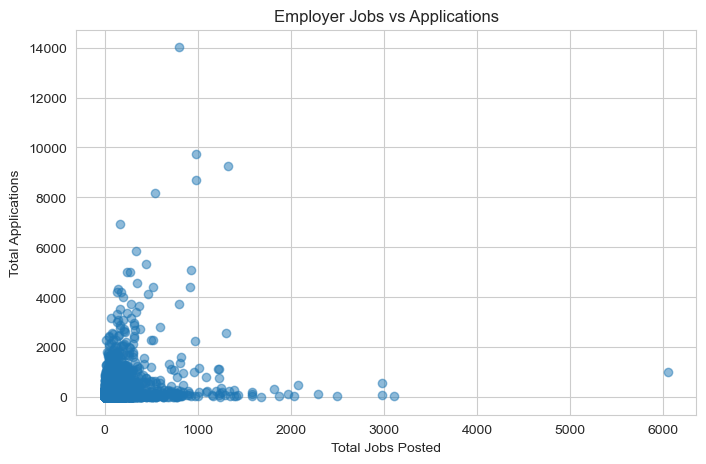

In [13]:
# Scatter plot of Jobs vs Applications
plt.figure(figsize=(8,5))
plt.scatter(employer_inf['total_jobs'], employer_inf['total_applications'], alpha=0.5)
plt.xlabel("Total Jobs Posted")
plt.ylabel("Total Applications")
plt.title("Employer Jobs vs Applications")
plt.show()

## Analyzing Event Participation
Focusing on what employers host events and weighting them based on student attendance

In [14]:
# Filter out invalid events
valid_events = ep_joined['events_name'].notna() & (ep_joined['events_name'].str.strip() != '')

# Count unique events per employer (deduplicated via events_id)
total_events = (
    ep_joined[valid_events]
    .dropna(subset=['events_id'])
    .drop_duplicates(subset=['employer_id', 'events_id'])
    .groupby('employer_id')['events_id']
    .count()
    .rename('total_events')
)

# Total student attendees per employer (deduplicated via events_id)
total_attendees = (
    ep_joined
    .dropna(subset=['events_id'])
    .drop_duplicates(subset=['employer_id', 'events_id'])
    .groupby('employer_id')['student_attendees_count']
    .sum()
    .rename('total_attendees')
)

# Add to employer_inf
if 'employer_name' not in employer_inf.columns:
    employer_inf['employer_name'] = ep_joined.groupby('employer_id')['employer_name'].first()

employer_inf['total_events'] = total_events
employer_inf['total_events'] = employer_inf['total_events'].fillna(0)
employer_inf['total_attendees'] = total_attendees
employer_inf['total_attendees'] = employer_inf['total_attendees'].fillna(0)

# Calculate Event Score
employer_inf['event_score'] = employer_inf['total_events'] + employer_inf['total_attendees']

In [15]:
#Summary Stats for event score column
event_score_stats = employer_inf['event_score'].describe()
event_score_stats

count    56089.000000
mean         1.207349
std         30.173252
min          0.000000
25%          0.000000
50%          0.000000
75%          0.000000
max       2718.000000
Name: event_score, dtype: float64

In [16]:
# Top 10 employers by Event Score
top_event_employers = employer_inf.sort_values('event_score', ascending=False)
top_event_employers[['employer_name','total_events','total_attendees','event_score']].head(10)

,employer_name,total_events,total_attendees,event_score
employer_id,,,,
9226,ey,314.0,2404.0,2718.0
39013,pwc,173.0,2261.0,2434.0
8594,deloitte,81.0,1890.0,1971.0
14620,mckinsey & company,165.0,1797.0,1962.0
11227,"google, inc.",96.0,1757.0,1853.0
12397,fidelity investments,71.0,1740.0,1811.0
14072,goldman sachs,129.0,1596.0,1725.0
8530,kpmg llp,158.0,1535.0,1693.0
13661,morgan stanley,185.0,1386.0,1571.0


In [17]:
# Bottom 10 employers by Event Score
bot_event_employers = employer_inf.sort_values('event_score', ascending=True)
bot_event_employers[['employer_name','total_events','total_attendees','event_score']].head(10)

,employer_name,total_events,total_attendees,event_score
employer_id,,,,
8406,von maur,0.0,0.0,0.0
578028,"xbiologix, inc",0.0,0.0,0.0
578085,oak knoll school of the holy child,0.0,0.0,0.0
578089,None,0.0,0.0,0.0
578117,None,0.0,0.0,0.0
578186,None,0.0,0.0,0.0
578189,damato chiropractic center,0.0,0.0,0.0
578197,None,0.0,0.0,0.0
578215,kr boston at keller williams,0.0,0.0,0.0


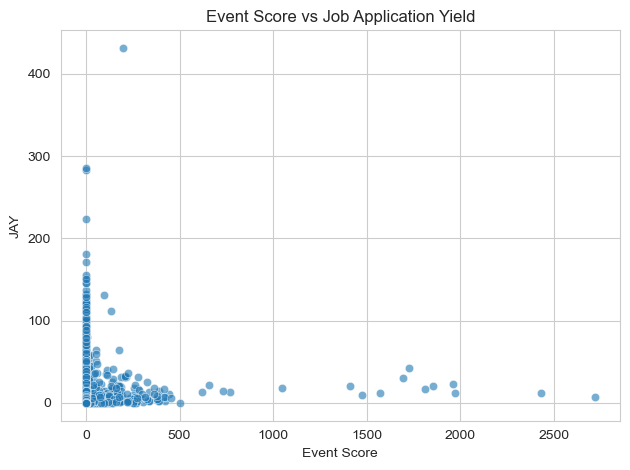

In [18]:
# ----------------------------
# Event Score vs JAY (New)
# ----------------------------

sns.scatterplot( data=employer_inf, x='event_score', y='JAY', alpha=0.6 )
plt.xlabel("Event Score")
plt.ylabel("JAY")
plt.title("Event Score vs Job Application Yield")
plt.tight_layout()
plt.show()

## Analyzing Employer Consistency
Separate Measures for Jobs and Events

In [19]:
# Make sure dates are datetime
ep_joined['job_creation_date'] = pd.to_datetime(ep_joined['job_creation_date'], errors='coerce')
ep_joined['event_date'] = pd.to_datetime(ep_joined['event_date'], errors='coerce')

# Calculate active years per employer for jobs
jobs_years = ep_joined.groupby('employer_id')['job_creation_date'].agg(['min','max'])
jobs_years['active_years_jobs'] = jobs_years['max'].dt.year - jobs_years['min'].dt.year + 1

# Calculate active years per employer for events
events_years = ep_joined.groupby('employer_id')['event_date'].agg(['min','max'])
events_years['active_years_events'] = events_years['max'].dt.year - events_years['min'].dt.year + 1

# Add directly to employer_inf
employer_inf['active_years_jobs'] = employer_inf.index.map(jobs_years['active_years_jobs'])
employer_inf['active_years_events'] = employer_inf.index.map(events_years['active_years_events'])
employer_inf['active_years_jobs'] = employer_inf['active_years_jobs'].fillna(0)
employer_inf['active_years_events'] = employer_inf['active_years_events'].fillna(0)

# Calculate consistency
total_possible_years = ep_joined['job_creation_date'].dt.year.max() - ep_joined['job_creation_date'].dt.year.min() + 1
employer_inf['consistency_jobs'] = employer_inf['active_years_jobs'] / total_possible_years
employer_inf['consistency_events'] = employer_inf['active_years_events'] / total_possible_years

In [20]:
#Summary stats for consistency column
employer_inf['consistency_jobs'].describe()

count    56089.000000
mean         0.227418
std          0.294288
min          0.000000
25%          0.000000
50%          0.166667
75%          0.333333
max          1.000000
Name: consistency_jobs, dtype: float64

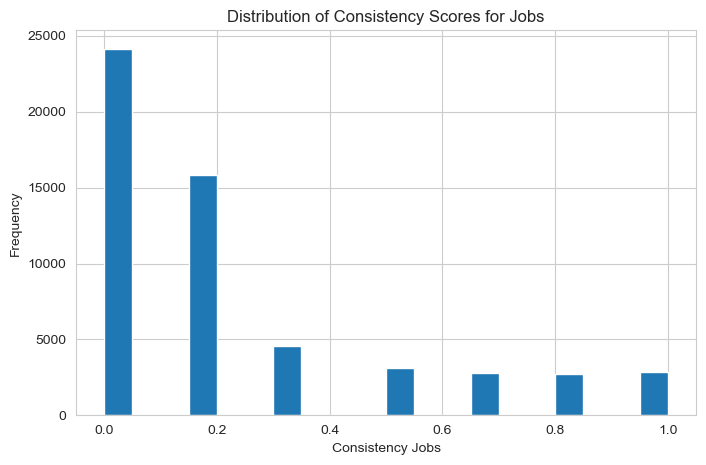

In [21]:
#Visualize Distribution of Consistency Scores for Jobs
plt.figure(figsize=(8,5))
plt.hist(employer_inf['consistency_jobs'], bins=20)
plt.xlabel('Consistency Jobs')
plt.ylabel('Frequency')
plt.title('Distribution of Consistency Scores for Jobs')
plt.show()

In [22]:
# View top 10 consistent employers for jobs
top_consistent_jobs = employer_inf.sort_values('consistency_jobs', ascending=False)
top_consistent_jobs[['employer_name','active_years_jobs','consistency_jobs']].head(10)

,employer_name,active_years_jobs,consistency_jobs
employer_id,,,
174269,y-12 national security complex,6.0,1.0
29767,nelson mullins riley & scarborough llp,6.0,1.0
174992,"western ecosystems technology, inc.",6.0,1.0
29784,neufeld scheck brustin hoffmann & freudenberge...,6.0,1.0
29822,new jersey future,6.0,1.0
175032,easterseals new hampshire,6.0,1.0
446986,truporch homes,6.0,1.0
175106,dhl express,6.0,1.0
175123,intermountain health,6.0,1.0


In [23]:
# View top 10 consistent employers for events
top_consistent_events = employer_inf.sort_values('consistency_events', ascending=False)
top_consistent_events[['employer_name','active_years_events','consistency_events']].head(10)

,employer_name,active_years_events,consistency_events
employer_id,,,
15767,wipfli,6.0,1.0
19110,aramark,6.0,1.0
12709,saga education,6.0,1.0
23924,mayo clinic,6.0,1.0
32606,yale university,6.0,1.0
11551,enterprise mobility,6.0,1.0
18583,burlington stores,6.0,1.0
12910,"fast enterprises, llc",6.0,1.0
21674,dana-farber cancer institute,6.0,1.0


In [24]:
# View top 10 inconsistent employers for jobs
top_inconsistent_jobs = (
    employer_inf[employer_inf['employer_name'].notna()]
    .sort_values('consistency_jobs', ascending=True)
)

top_inconsistent_jobs[['employer_name','active_years_jobs','consistency_jobs']].head(10)

,employer_name,active_years_jobs,consistency_jobs
employer_id,,,
1061634,alumboost,1.0,0.166667
200261,central kentucky ag credit,1.0,0.166667
709985,space craft,1.0,0.166667
200316,black lab sports,1.0,0.166667
200322,bollore logistics,1.0,0.166667
200336,city of seattle parks and recreation department,1.0,0.166667
709976,fashion for all foundation,1.0,0.166667
200419,kongbasileconsulting,1.0,0.166667
709921,"discovery mental health counseling, pllc",1.0,0.166667


In [25]:
# View top 10 inconsistent employers for events
top_inconsistent_events = (
    employer_inf[employer_inf['employer_name'].notna()]
    .sort_values('consistency_events', ascending=True)
)

top_inconsistent_events[['employer_name','active_years_events','consistency_events']].head(10)

,employer_name,active_years_events,consistency_events
employer_id,,,
8406,von maur,0.0,0.0
633724,university of notre dame - oit help desk,0.0,0.0
633699,tbc - the beach club centerville,0.0,0.0
633592,vision solar llc,0.0,0.0
633589,beginning years child development center,0.0,0.0
633544,tropic,0.0,0.0
633532,"s. lichtenberg & co., inc.",0.0,0.0
633470,kured,0.0,0.0
633469,corner co-op nursery school,0.0,0.0


**Note:** Some employer ids were associated with missing employer names and were dropped in the top_inconsistent dfs

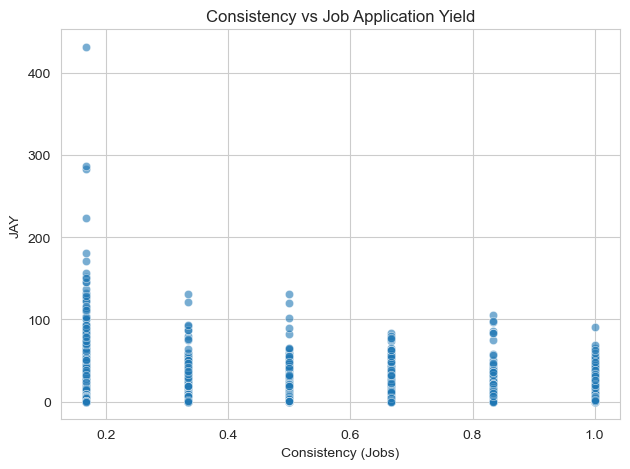

In [26]:
# -----------------------------
# Consistency vs JAY (new)
# -----------------------------

sns.scatterplot( data=employer_inf, x='consistency_jobs', y='JAY', alpha=0.6 )
plt.xlabel("Consistency (Jobs)")
plt.ylabel("JAY")
plt.title("Consistency vs Job Application Yield")
plt.tight_layout()
plt.show()

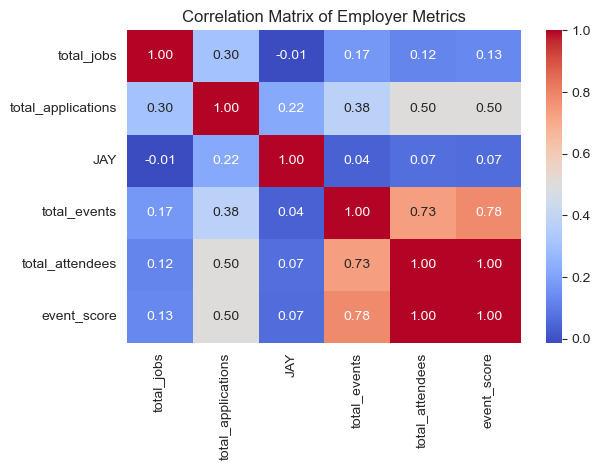

In [27]:
# -----------------------------
# Correlation Heatmap (New)
# -----------------------------

corr_cols = ['total_jobs','total_applications','JAY','total_events','total_attendees','event_score']
corr = employer_inf[corr_cols].corr()
sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Matrix of Employer Metrics")
plt.tight_layout()
plt.show()

## KPI Engineering Extension
Added by: Abigail Merage

Builds on `employer_inf` to add missing KPIs:
- **EAY** – Event Attendance Yield (corrected dedup via `events_id`)
- **EEB** – Employer Engagement Breadth
- **EEC** – Unified Engagement Consistency (jobs + events combined)
- **ACI** – Application Concentration Index
- **SSI** – Salary Signaling Index (exploratory)
- **EEIS** – Composite Employer Engagement Intensity Score
- Employer type enrichment + segmentation visuals

### Event Attendance Yield (EAY)
**EAY = Student Attendees / Events Hosted**

Recomputes event counts using `events_id.nunique()` per employer, mirroring how `total_jobs` uses `jobs_id.nunique()`. The existing `total_events` column uses `events_name.count()` on raw rows, which can overcount when an employer appears across multiple job rows in the joined dataset.

In [28]:
# EAY - Event Attendance Yield (deduplicated via events_id)
events_df = ep_joined.dropna(subset=['events_id']).copy()
events_df = events_df.drop_duplicates(subset=['employer_id', 'events_id'])

events_emp = events_df.groupby('employer_id').agg(
    total_events_dedup=('events_id', 'count'),
    total_attendees_dedup=('student_attendees_count', 'sum')
).reset_index()

events_emp['EAY'] = events_emp['total_attendees_dedup'] / events_emp['total_events_dedup']

employer_inf = employer_inf.merge(
    events_emp[['employer_id', 'total_events_dedup', 'total_attendees_dedup', 'EAY']],
    on='employer_id', how='left'
)

print('Top 10 employers by Event Attendance Yield (EAY):')
employer_inf[['employer_name', 'total_events', 'total_attendees', 'EAY']]\
    .sort_values('EAY', ascending=False).head(10)

Top 10 employers by Event Attendance Yield (EAY):


,employer_name,total_events,total_attendees,EAY
5066,year up,1.0,269.0,269.00
17188,newmark,1.0,255.0,255.00
32314,bartaco restaurants,1.0,224.0,224.00
21071,the goddard school of watertown and milton,1.0,223.0,223.00
7342,puma,1.0,220.0,220.00
1595,putnam investments,2.0,415.0,207.50
2245,asml,2.0,375.0,187.50
1477,"shell usa, inc.",1.0,186.0,186.00
42092,"questrom school of business, boston university",4.0,731.0,182.75
26727,christian dior inc.,2.0,361.0,180.50


### Employer Engagement Breadth (EEB)
**EEB = 1(Posted Jobs) + 1(Hosted Events)**

Binary indicator of how many Handshake channels an employer uses. EEB=2 means both jobs and events; EEB=1 means one channel only; EEB=0 means inactive.

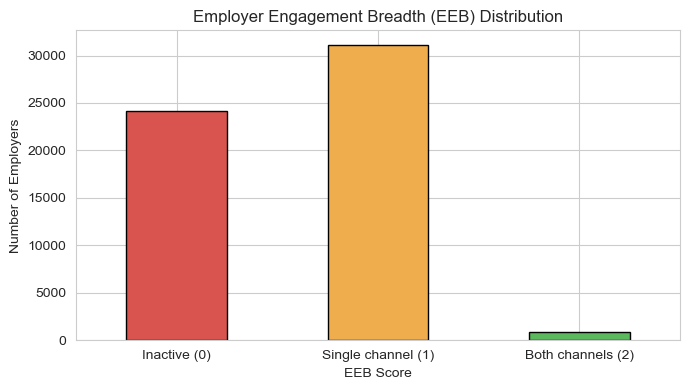

Inactive (0)          24111
Single channel (1)    31092
Both channels (2)       886
Name: count, dtype: int64


In [29]:
# EEB - Employer Engagement Breadth
employer_inf['EEB'] = (
    (employer_inf['total_jobs'] > 0).astype(int) +
    (employer_inf['total_events'].fillna(0) > 0).astype(int)
)

eeb_counts = employer_inf['EEB'].value_counts().sort_index()
labels = {0: 'Inactive (0)', 1: 'Single channel (1)', 2: 'Both channels (2)'}
eeb_counts.index = [labels.get(i, str(i)) for i in eeb_counts.index]

plt.figure(figsize=(7, 4))
eeb_counts.plot(kind='bar', color=['#d9534f', '#f0ad4e', '#5cb85c'], edgecolor='black')
plt.title('Employer Engagement Breadth (EEB) Distribution')
plt.xlabel('EEB Score')
plt.ylabel('Number of Employers')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

print(eeb_counts)

### Employer Engagement Consistency (EEC) - Unified
**EEC = Active Years (jobs OR events) / Years Since First Activity**

Pools calendar years from both unique job postings and unique events per employer. This is the unified version of the separate `consistency_jobs` and `consistency_events` columns computed above. An employer that posted jobs in 2020 and hosted events in 2022 gets credit for both years in the numerator.

In [30]:
# EEC - Unified Engagement Consistency
jobs_df2 = ep_joined.dropna(subset=['jobs_id']).drop_duplicates(subset=['employer_id', 'jobs_id']).copy()
jobs_df2['activity_year'] = pd.to_datetime(jobs_df2['job_creation_date'], errors='coerce').dt.year
job_years = jobs_df2[['employer_id', 'activity_year']].dropna()

events_df3 = ep_joined.dropna(subset=['events_id']).drop_duplicates(subset=['employer_id', 'events_id']).copy()
events_df3['activity_year'] = pd.to_datetime(events_df3['event_date'], errors='coerce').dt.year
event_years = events_df3[['employer_id', 'activity_year']].dropna()

all_years = pd.concat([job_years, event_years], ignore_index=True).drop_duplicates()

years_summary = all_years.groupby('employer_id')['activity_year'].agg(
    active_years_unified='nunique',
    first_year='min',
    last_year='max'
).reset_index()

years_summary['years_span'] = years_summary['last_year'] - years_summary['first_year'] + 1
years_summary['EEC'] = years_summary['active_years_unified'] / years_summary['years_span']

employer_inf = employer_inf.merge(
    years_summary[['employer_id', 'active_years_unified', 'years_span', 'EEC']],
    on='employer_id', how='left'
)

print(f"Employers with EEC = 1.0 (active every year in span): {(employer_inf['EEC'] == 1.0).sum()}")
print(f"Mean EEC: {employer_inf['EEC'].mean():.3f}")
employer_inf[['employer_name', 'active_years_unified', 'years_span', 'EEC']]\
    .sort_values('EEC', ascending=False).head(10)

Employers with EEC = 1.0 (active every year in span): 27413
Mean EEC: 0.955


,employer_name,active_years_unified,years_span,EEC
0,von maur,2.0,2.0,1.0
39562,malta inc.,1.0,1.0,1.0
39593,fuel sales academy,1.0,1.0,1.0
39590,"fidelis investors, llc",2.0,2.0,1.0
39582,"texas enterprises, inc.",1.0,1.0,1.0
39581,the farm school,1.0,1.0,1.0
39577,sharper shape,1.0,1.0,1.0
39576,"somos innovation, llc",1.0,1.0,1.0
39573,seaworld parks & entertainment,2.0,2.0,1.0
39572,genie healthcare,1.0,1.0,1.0


### Application Concentration Index (ACI)
**ACI = max(Applications per Job) / Total Applications**

Measures whether student interest is spread evenly across postings or concentrated in one job. ACI = 1.0 means all applications went to a single posting. Low ACI means student interest is distributed broadly. Computed only for employers with total_applications > 0.

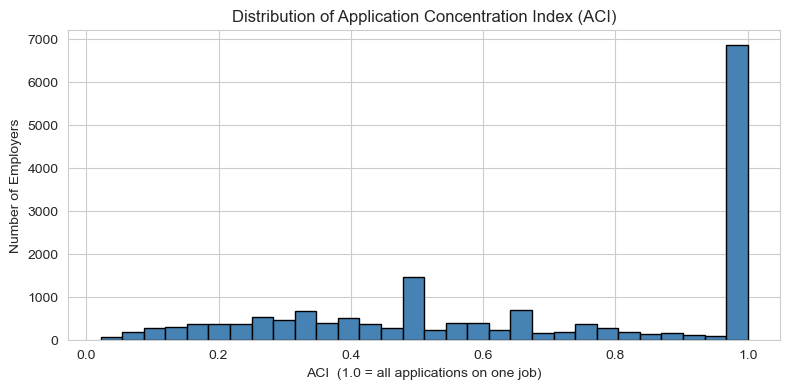

Median ACI: 0.667
Employers with ACI = 1.0: 6829  (39.3% of employers with applications)


In [31]:
# ACI - Application Concentration Index
jobs_aci = ep_joined.dropna(subset=['jobs_id']).drop_duplicates(subset=['employer_id', 'jobs_id']).copy()

aci_agg = jobs_aci.groupby('employer_id').agg(
    max_apps_job=('applications_count', 'max'),
    total_apps_check=('applications_count', 'sum')
).reset_index()

aci_agg['ACI'] = np.where(
    aci_agg['total_apps_check'] > 0,
    aci_agg['max_apps_job'] / aci_agg['total_apps_check'],
    np.nan
)

employer_inf = employer_inf.merge(aci_agg[['employer_id', 'ACI']], on='employer_id', how='left')

aci_valid = employer_inf['ACI'].dropna()
plt.figure(figsize=(8, 4))
plt.hist(aci_valid, bins=30, edgecolor='black', color='steelblue')
plt.title('Distribution of Application Concentration Index (ACI)')
plt.xlabel('ACI  (1.0 = all applications on one job)')
plt.ylabel('Number of Employers')
plt.tight_layout()
plt.show()

print(f"Median ACI: {aci_valid.median():.3f}")
print(f"Employers with ACI = 1.0: {(aci_valid == 1.0).sum()} ",
      f"({100*(aci_valid==1.0).mean():.1f}% of employers with applications)")

### Salary Signaling Index (SSI)
**SSI = Avg Salary Midpoint x JAY**

Shows whether compensation levels correlate with attracting student applications. Salary midpoint = (min_salary + max_salary) / 2 per unique job. Zero-salary rows excluded (likely missing data). > Treated as exploratory due to known salary data quality issues from Milestone 1.

In [32]:
# SSI - Salary Signaling Index (exploratory)
jobs_sal = ep_joined.dropna(subset=['jobs_id']).drop_duplicates(subset=['employer_id', 'jobs_id']).copy()
jobs_sal['salary_mid'] = (jobs_sal['min_salary'].fillna(0) + jobs_sal['max_salary'].fillna(0)) / 2
jobs_sal_nonzero = jobs_sal[jobs_sal['salary_mid'] > 0]

avg_salary = jobs_sal_nonzero.groupby('employer_id')['salary_mid'].mean().reset_index()
avg_salary.columns = ['employer_id', 'avg_salary_mid']

employer_inf = employer_inf.merge(avg_salary, on='employer_id', how='left')
employer_inf['SSI'] = employer_inf['avg_salary_mid'] * employer_inf['JAY']

print('Top 10 employers by Salary Signaling Index (SSI):')
employer_inf.dropna(subset=['SSI']).sort_values('SSI', ascending=False)\
    [['employer_name', 'avg_salary_mid', 'JAY', 'SSI']].head(10)

Top 10 employers by Salary Signaling Index (SSI):


,employer_name,avg_salary_mid,JAY,SSI
53183,fundamental research labs,200000.000000,181.000000,3.620000e+07
3283,delta partners,50750.000000,431.000000,2.187325e+07
52261,ikigai labs,136666.666667,114.666667,1.567111e+07
32951,aquatic,175000.000000,71.000000,1.242500e+07
9805,cogo labs,136945.000000,86.333333,1.182292e+07
3606,newbury partners,141667.000000,81.666667,1.156947e+07
51965,marston limited,92500.000000,122.000000,1.128500e+07
52529,tetricus labs,140000.000000,80.000000,1.120000e+07
15302,mcmann & ransford,80000.000000,131.000000,1.048000e+07
52982,n1 health,111666.666667,92.666667,1.034778e+07


### Employer Engagement Intensity Score (EEIS)
**EEIS = w1(Jobs) + w2(Events) + w3(Applications) + w4(Attendees)**

Composite engagement score. Each of the four input channels is min-max scaled to [0,1] then combined with equal weights (0.25 each). Reflects how deeply an employer engages with BU students across multiple Handshake channels.

In [33]:
# EEIS - Composite Employer Engagement Intensity Score
from sklearn.preprocessing import MinMaxScaler

eeis_input = employer_inf[['total_jobs', 'total_events', 'total_applications', 'total_attendees']].fillna(0)

scaler = MinMaxScaler()
normed = scaler.fit_transform(eeis_input)

w1, w2, w3, w4 = 0.25, 0.25, 0.25, 0.25
employer_inf['EEIS'] = w1*normed[:,0] + w2*normed[:,1] + w3*normed[:,2] + w4*normed[:,3]

print('Top 10 employers by EEIS (composite engagement):')
employer_inf.sort_values('EEIS', ascending=False)\
    [['employer_name', 'total_jobs', 'total_events', 'total_applications', 'total_attendees', 'EEIS']].head(10)

Top 10 employers by EEIS (composite engagement):


,employer_name,total_jobs,total_events,total_applications,total_attendees,EEIS
135,ey,383,314.0,2723.0,2404.0,0.564389
1731,jpmorganchase,985,109.0,9732.0,1366.0,0.443114
2461,amazon,795,61.0,14015.0,989.0,0.434246
4947,pwc,221,173.0,2615.0,2261.0,0.428640
759,morgan stanley,450,185.0,5346.0,1386.0,0.405373
921,mckinsey & company,178,165.0,4198.0,1797.0,0.400480
838,goldman sachs,164,129.0,6919.0,1596.0,0.398874
32,kpmg llp,140,158.0,4326.0,1535.0,0.368375
728,capital one,27,246.0,549.0,1164.0,0.327816
46,deloitte,213,81.0,2654.0,1890.0,0.317176


### Employer Type Enrichment
Merges `employer_type` and size from `ep_base_cleaned.csv` to enable engagement breakdowns by industry sector.

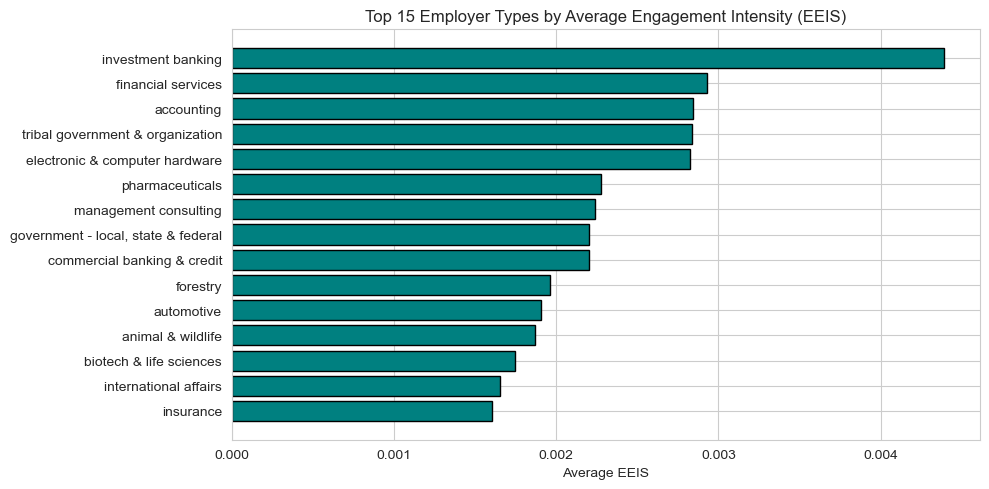

In [34]:
# Employer type enrichment from ep_base_cleaned
ep_base = pd.read_csv(os.path.join(DATA_DIR, 'ep_base_cleaned.csv'), low_memory=False)

base_attrs = ep_base[['employer_id', 'employer_type', 'employer_size_min', 'employer_size_max']]\
    .drop_duplicates(subset=['employer_id']).copy()
base_attrs['employer_size_mid'] = (
    base_attrs['employer_size_min'].fillna(0) + base_attrs['employer_size_max'].fillna(0)
) / 2

employer_inf = employer_inf.merge(base_attrs, on='employer_id', how='left')

# Average EEIS by employer type (top 15 by count)
type_eeis = employer_inf.dropna(subset=['employer_type', 'EEIS'])\
    .groupby('employer_type').agg(
        avg_EEIS=('EEIS', 'mean'),
        count=('employer_id', 'count')
    ).reset_index().sort_values('avg_EEIS', ascending=False).head(15)

plt.figure(figsize=(10, 5))
plt.barh(type_eeis['employer_type'][::-1], type_eeis['avg_EEIS'][::-1], color='teal', edgecolor='black')
plt.xlabel('Average EEIS')
plt.title('Top 15 Employer Types by Average Engagement Intensity (EEIS)')
plt.tight_layout()
plt.show()

### Employer Segmentation: EEB x EEC
Segments employers by breadth (channels used) and consistency (regularity of engagement). Four quadrants for the CCD slide deck:
- **Core Partners**: EEB=2, high EEC (both channels, consistent)
- **Sporadic Multi-Channel**: EEB=2, low EEC (both channels, irregular)
- **Loyal Single-Channel**: EEB=1, high EEC (one channel, consistent)
- **Peripheral**: EEB=0 or low EEC (minimal engagement)

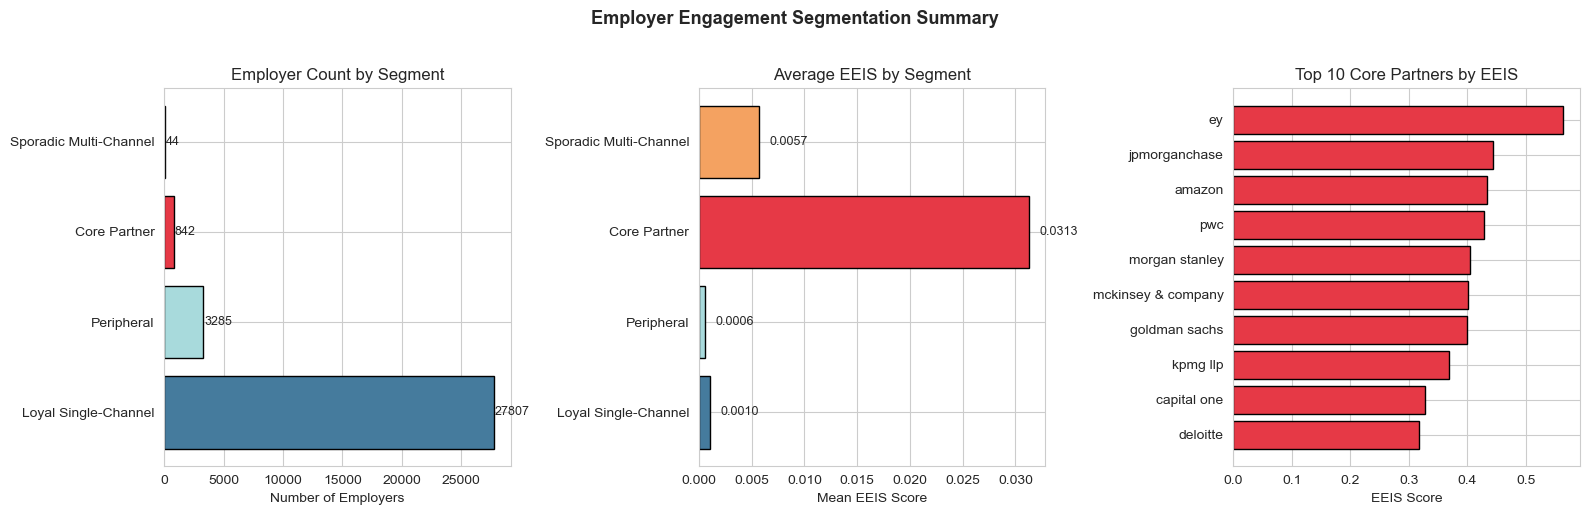


Segment Summary:


,count,avg_EEIS,avg_EEC,avg_jobs
segment,,,,
Core Partner,842,0.031,0.989,149.280
Loyal Single-Channel,27807,0.001,0.992,14.849
Peripheral,3285,0.001,0.634,7.155
Sporadic Multi-Channel,44,0.006,0.633,11.591


In [35]:
seg = employer_inf.dropna(subset=['EEC', 'EEB', 'EEIS']).copy()
seg = seg[seg['EEB'] > 0]

eec_threshold = 0.8
seg['segment'] = 'Loyal Single-Channel'
seg.loc[(seg['EEB'] == 2) & (seg['EEC'] >= eec_threshold), 'segment'] = 'Core Partner'
seg.loc[(seg['EEB'] == 2) & (seg['EEC'] < eec_threshold), 'segment'] = 'Sporadic Multi-Channel'
seg.loc[(seg['EEB'] < 2) & (seg['EEC'] < eec_threshold), 'segment'] = 'Peripheral'

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# Plot 1: Segment size 
seg_counts = seg['segment'].value_counts()
colors = {'Core Partner': '#e63946', 'Sporadic Multi-Channel': '#f4a261',
          'Loyal Single-Channel': '#457b9d', 'Peripheral': '#a8dadc'}
bar_colors = [colors[s] for s in seg_counts.index]

axes[0].barh(seg_counts.index, seg_counts.values, color=bar_colors, edgecolor='black')
axes[0].set_title('Employer Count by Segment')
axes[0].set_xlabel('Number of Employers')
for i, v in enumerate(seg_counts.values):
    axes[0].text(v + 50, i, str(v), va='center', fontsize=9)

# Plot 2: Average EEIS per segment 
seg_eeis = seg.groupby('segment')['EEIS'].mean().reindex(seg_counts.index)
bar_colors2 = [colors[s] for s in seg_eeis.index]

axes[1].barh(seg_eeis.index, seg_eeis.values, color=bar_colors2, edgecolor='black')
axes[1].set_title('Average EEIS by Segment')
axes[1].set_xlabel('Mean EEIS Score')
for i, v in enumerate(seg_eeis.values):
    axes[1].text(v + 0.001, i, f'{v:.4f}', va='center', fontsize=9)

# Plot 3: Top 10 Core Partners by EEIS 
top_core = seg[seg['segment'] == 'Core Partner'].sort_values('EEIS', ascending=False).head(10)
axes[2].barh(top_core['employer_name'][::-1], top_core['EEIS'][::-1],
             color='#e63946', edgecolor='black')
axes[2].set_title('Top 10 Core Partners by EEIS')
axes[2].set_xlabel('EEIS Score')

plt.suptitle('Employer Engagement Segmentation Summary', fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

# Segment summary table
print("\nSegment Summary:")
summary = seg.groupby('segment').agg(
    count=('EEIS', 'count'),
    avg_EEIS=('EEIS', 'mean'),
    avg_EEC=('EEC', 'mean'),
    avg_jobs=('total_jobs', 'mean'),
).round(3)
display(summary)

### Full Employer KPI Summary Table
Consolidated view of all KPIs. Sorted by EEIS descending.

In [42]:
# Full employer KPI summary
kpi_cols = [
    'employer_name', 'employer_type',
    'total_jobs', 'total_applications', 'JAY',
    'total_events', 'total_attendees', 'EAY',
    'EEB', 'EEC', 'ACI', 'avg_salary_mid', 'SSI', 'EEIS'
]
available = [c for c in kpi_cols if c in employer_inf.columns]
kpi_summary = employer_inf[available].sort_values('EEIS', ascending=False)
print(f'Total employers in KPI table: {len(kpi_summary)}')
kpi_summary.head(20)

Total employers in KPI table: 56089


,employer_name,employer_type,total_jobs,total_applications,JAY,total_events,total_attendees,EAY,EEB,EEC,ACI,avg_salary_mid,SSI,EEIS
135,ey,accounting,383,2723.0,7.109661,314.0,2404.0,7.656051,2,1.0,0.030114,21646.981974,1.539027e+05,0.564389
1731,jpmorganchase,financial services,985,9732.0,9.880203,109.0,1366.0,12.532110,2,1.0,0.034423,62418.286487,6.167053e+05,0.443114
2461,amazon,internet & software,795,14015.0,17.628931,61.0,989.0,16.213115,2,1.0,0.032394,19182.575407,3.381683e+05,0.434246
4947,pwc,accounting,221,2615.0,11.832579,173.0,2261.0,13.069364,2,1.0,0.041300,34755.373967,4.112457e+05,0.428640
759,morgan stanley,investment banking,450,5346.0,11.880000,185.0,1386.0,7.491892,2,1.0,0.027123,31195.901818,3.706073e+05,0.405373
921,mckinsey & company,management consulting,178,4198.0,23.584270,165.0,1797.0,10.890909,2,1.0,0.061934,150106.097317,3.540143e+06,0.400480
838,goldman sachs,investment banking,164,6919.0,42.189024,129.0,1596.0,12.372093,2,1.0,0.076023,65613.856429,2.768185e+06,0.398874
32,kpmg llp,accounting,140,4326.0,30.900000,158.0,1535.0,9.715190,2,1.0,0.073509,3168.416667,9.790407e+04,0.368375
728,capital one,commercial banking & credit,27,549.0,20.333333,246.0,1164.0,4.731707,2,1.0,0.262295,201257.142857,4.092229e+06,0.327816
46,deloitte,management consulting,213,2654.0,12.460094,81.0,1890.0,23.333333,2,1.0,0.086662,23689.746944,2.951765e+05,0.317176


# Some Unanswered Questions by the KPIs

## Event Type Analysis
Identifies common event types by parsing `events_name` into categories. Addresses task: *Identify highly engaged employers, common event types, and engagement trends.*

Event Type Summary:


,event_type,event_count,total_attendees,avg_attendees
4,Other,4979,28437.0,5.71
1,Info Session,1923,11141.0,5.79
7,Workshop/Webinar,751,3435.0,4.57
5,Panel/Speaker,479,5299.0,11.06
6,Recruiting/Interview,371,2476.0,6.67
0,Career Fair,346,2093.0,6.05
3,Open House/Coffee Chat,292,2172.0,7.44
2,Networking,219,3306.0,15.10


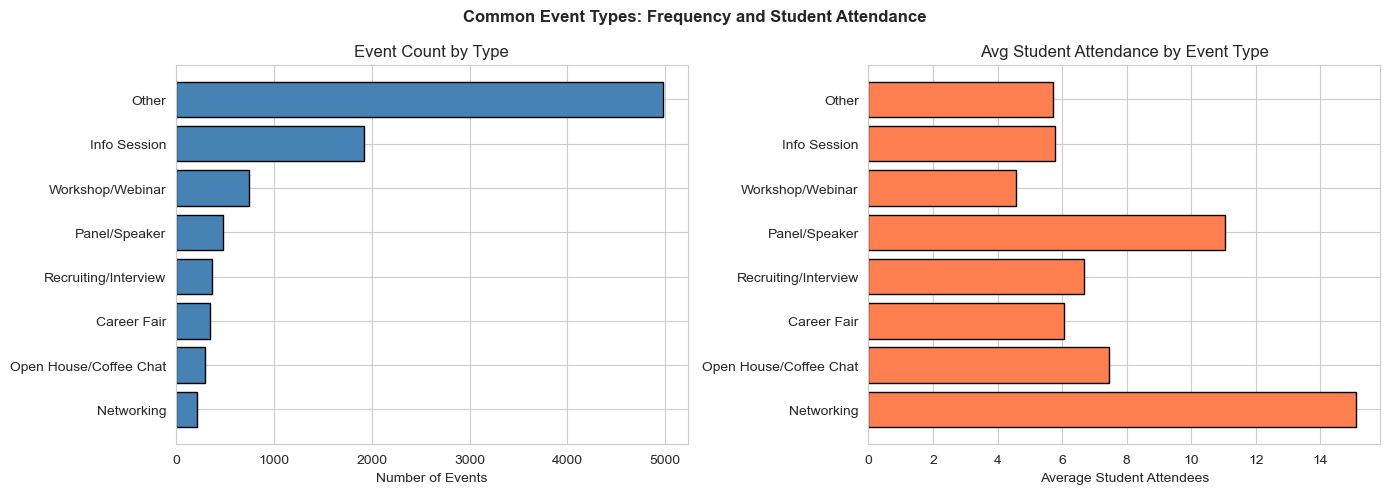

In [37]:
# Event type categorization from events_name
events_clean = ep_joined.dropna(subset=['events_id']).drop_duplicates(subset=['events_id']).copy()
events_clean['events_name_lower'] = events_clean['events_name'].str.lower().str.strip()

def categorize_event(name):
    if any(k in name for k in ['career fair', 'job fair', 'hiring fair']):
        return 'Career Fair'
    elif any(k in name for k in ['info session', 'information session', 'infosession']):
        return 'Info Session'
    elif any(k in name for k in ['networking', 'network']):
        return 'Networking'
    elif any(k in name for k in ['workshop', 'seminar', 'training', 'webinar']):
        return 'Workshop/Webinar'
    elif any(k in name for k in ['interview', 'recruiting', 'recruitment']):
        return 'Recruiting/Interview'
    elif any(k in name for k in ['panel', 'speaker', 'talk', 'presentation']):
        return 'Panel/Speaker'
    elif any(k in name for k in ['open house', 'office hour', 'coffee chat']):
        return 'Open House/Coffee Chat'
    else:
        return 'Other'

events_clean['event_type'] = events_clean['events_name_lower'].apply(categorize_event)

# Count and attendees per event type
event_type_summary = events_clean.groupby('event_type').agg(
    event_count=('events_id', 'count'),
    total_attendees=('student_attendees_count', 'sum'),
    avg_attendees=('student_attendees_count', 'mean')
).reset_index().sort_values('event_count', ascending=False)

print('Event Type Summary:')
display(event_type_summary.round(2))

# Plot
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].barh(event_type_summary['event_type'][::-1],
             event_type_summary['event_count'][::-1],
             color='steelblue', edgecolor='black')
axes[0].set_xlabel('Number of Events')
axes[0].set_title('Event Count by Type')

axes[1].barh(event_type_summary['event_type'][::-1],
             event_type_summary['avg_attendees'][::-1],
             color='coral', edgecolor='black')
axes[1].set_xlabel('Average Student Attendees')
axes[1].set_title('Avg Student Attendance by Event Type')

plt.suptitle('Common Event Types: Frequency and Student Attendance', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

## Engagement Trends Over Time
Year-over-year trends for job postings, applications, and event hosting. Addresses task: *Identify engagement trends* and *Analyze employer activity on Handshake.*

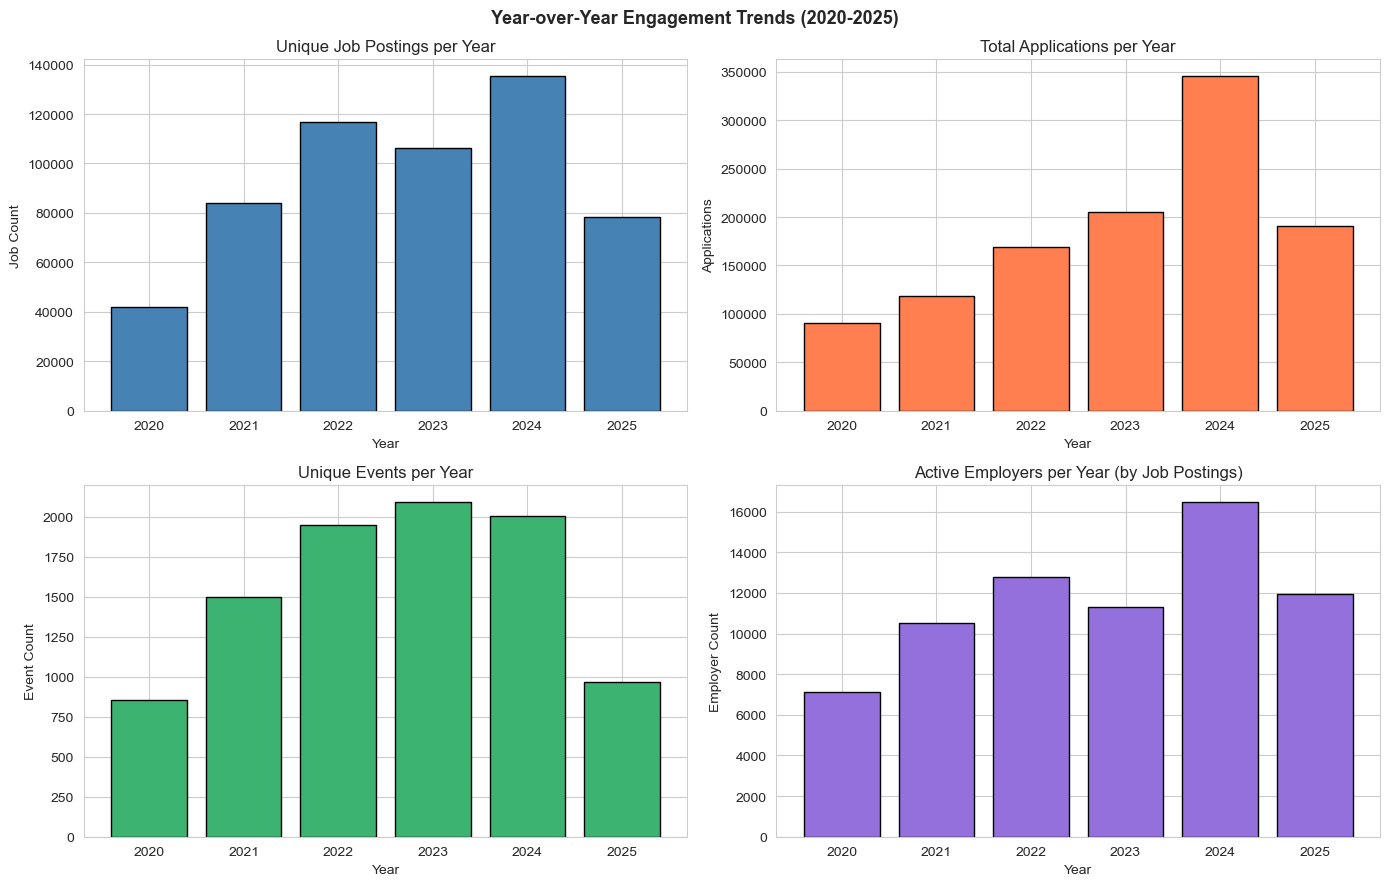

In [38]:
# Year-over-year engagement trends

# Jobs and applications by year (unique jobs)
jobs_yearly = ep_joined.dropna(subset=['jobs_id']).drop_duplicates(subset=['jobs_id']).copy()
jobs_yearly['year'] = pd.to_datetime(jobs_yearly['job_creation_date'], errors='coerce').dt.year
jobs_by_year = jobs_yearly.groupby('year').agg(
    unique_jobs=('jobs_id', 'count'),
    total_applications=('applications_count', 'sum'),
    active_employers=('employer_id', 'nunique')
).reset_index().dropna(subset=['year'])
jobs_by_year['year'] = jobs_by_year['year'].astype(int)

# Events by year (unique events)
events_yearly = ep_joined.dropna(subset=['events_id']).drop_duplicates(subset=['events_id']).copy()
events_yearly['year'] = pd.to_datetime(events_yearly['event_date'], errors='coerce').dt.year
events_by_year = events_yearly.groupby('year').agg(
    unique_events=('events_id', 'count'),
    total_attendees=('student_attendees_count', 'sum')
).reset_index().dropna(subset=['year'])
events_by_year['year'] = events_by_year['year'].astype(int)

fig, axes = plt.subplots(2, 2, figsize=(14, 9))

# Jobs posted per year
axes[0,0].bar(jobs_by_year['year'], jobs_by_year['unique_jobs'], color='steelblue', edgecolor='black')
axes[0,0].set_title('Unique Job Postings per Year')
axes[0,0].set_xlabel('Year')
axes[0,0].set_ylabel('Job Count')

# Applications per year
axes[0,1].bar(jobs_by_year['year'], jobs_by_year['total_applications'], color='coral', edgecolor='black')
axes[0,1].set_title('Total Applications per Year')
axes[0,1].set_xlabel('Year')
axes[0,1].set_ylabel('Applications')

# Events per year
axes[1,0].bar(events_by_year['year'], events_by_year['unique_events'], color='mediumseagreen', edgecolor='black')
axes[1,0].set_title('Unique Events per Year')
axes[1,0].set_xlabel('Year')
axes[1,0].set_ylabel('Event Count')

# Active employers per year
axes[1,1].bar(jobs_by_year['year'], jobs_by_year['active_employers'], color='mediumpurple', edgecolor='black')
axes[1,1].set_title('Active Employers per Year (by Job Postings)')
axes[1,1].set_xlabel('Year')
axes[1,1].set_ylabel('Employer Count')

plt.suptitle('Year-over-Year Engagement Trends (2020-2025)', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

## Student Engagement Analysis
Examines student engagement through event attendance and application behavior. Addresses task: *Examine student engagement through applications and event attendance.*

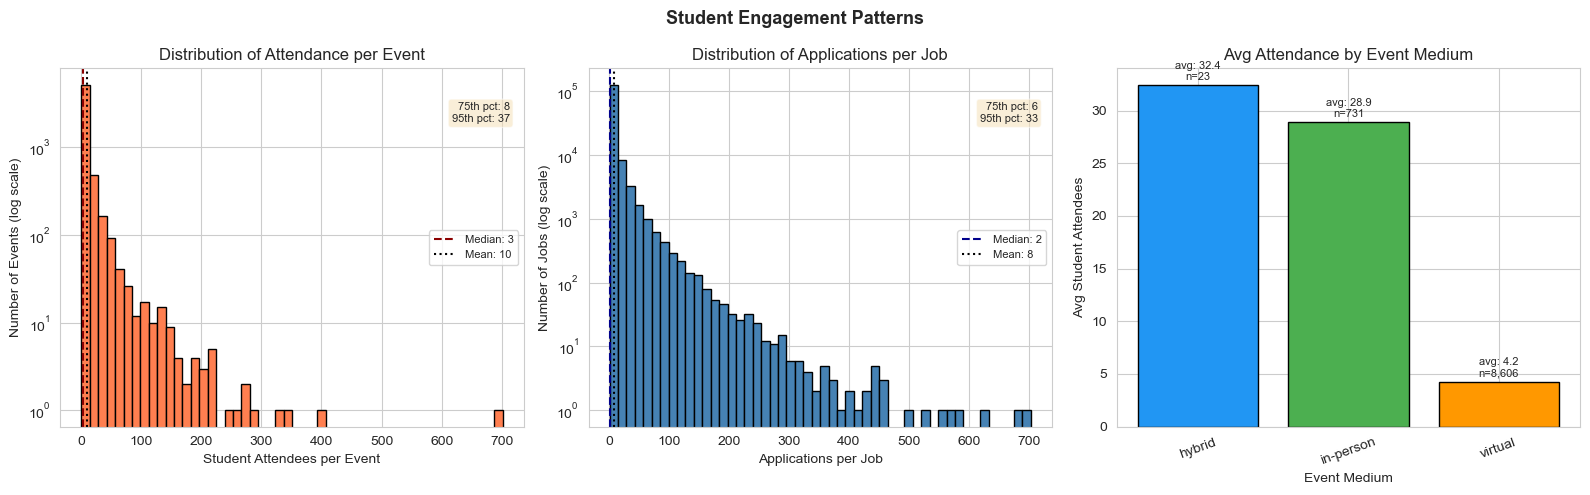

Attendance per event:
count    6038.0
mean        9.7
std        23.5
min         1.0
25%         1.0
50%         3.0
75%         8.0
max       701.0
Name: student_attendees_count, dtype: float64

Applications per job:
count    141912.0
mean          7.9
std          19.1
min           1.0
25%           1.0
50%           2.0
75%           6.0
max         703.0
Name: applications_count, dtype: float64

Event medium breakdown:
event_medium  avg_attendees  event_count
      hybrid      32.391304           23
   in-person      28.880985          731
     virtual       4.241459         8606


In [40]:
# Student engagement: attendance and application patterns

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# 1. Attendance per event — log scale to show full distribution
axes[0].hist(att_per_event_filtered, bins=50, color='coral', edgecolor='black', log=True)
axes[0].set_xlabel('Student Attendees per Event')
axes[0].set_ylabel('Number of Events (log scale)')
axes[0].set_title('Distribution of Attendance per Event')
axes[0].axvline(att_per_event_filtered.median(), color='darkred', linestyle='--',
                label=f'Median: {att_per_event_filtered.median():.0f}')
axes[0].axvline(att_per_event_filtered.mean(), color='black', linestyle=':',
                label=f'Mean: {att_per_event_filtered.mean():.0f}')
axes[0].legend(fontsize=8)

# Add percentile annotation
p75 = att_per_event_filtered.quantile(0.75)
p95 = att_per_event_filtered.quantile(0.95)
axes[0].text(0.97, 0.85, f'75th pct: {p75:.0f}\n95th pct: {p95:.0f}',
             transform=axes[0].transAxes, ha='right', fontsize=8,
             bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))

# 2. Applications per job — log scale
axes[1].hist(apps_per_job_filtered, bins=50, color='steelblue', edgecolor='black', log=True)
axes[1].set_xlabel('Applications per Job')
axes[1].set_ylabel('Number of Jobs (log scale)')
axes[1].set_title('Distribution of Applications per Job')
axes[1].axvline(apps_per_job_filtered.median(), color='darkblue', linestyle='--',
                label=f'Median: {apps_per_job_filtered.median():.0f}')
axes[1].axvline(apps_per_job_filtered.mean(), color='black', linestyle=':',
                label=f'Mean: {apps_per_job_filtered.mean():.0f}')
axes[1].legend(fontsize=8)

p75_apps = apps_per_job_filtered.quantile(0.75)
p95_apps = apps_per_job_filtered.quantile(0.95)
axes[1].text(0.97, 0.85, f'75th pct: {p75_apps:.0f}\n95th pct: {p95_apps:.0f}',
             transform=axes[1].transAxes, ha='right', fontsize=8,
             bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))

# 3. Avg attendance by medium — add count labels and sort
bars = axes[2].bar(medium_attendance['event_medium'],
                   medium_attendance['mean'],
                   color=['#2196F3', '#4CAF50', '#FF9800'][:len(medium_attendance)],
                   edgecolor='black')
axes[2].set_xlabel('Event Medium')
axes[2].set_ylabel('Avg Student Attendees')
axes[2].set_title('Avg Attendance by Event Medium')
axes[2].tick_params(axis='x', rotation=20)

# Add value + event count labels on bars
for bar, (_, row) in zip(bars, medium_attendance.iterrows()):
    axes[2].text(bar.get_x() + bar.get_width()/2,
                 bar.get_height() + 0.3,
                 f"avg: {row['mean']:.1f}\nn={int(row['count']):,}",
                 ha='center', va='bottom', fontsize=8)

plt.suptitle('Student Engagement Patterns', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

# Summary stats
print("Attendance per event:")
print(att_per_event_filtered.describe().round(1))
print("\nApplications per job:")
print(apps_per_job_filtered.describe().round(1))
print("\nEvent medium breakdown:")
print(medium_attendance.rename(columns={'mean': 'avg_attendees', 'count': 'event_count'}).to_string(index=False))